MULTIPLE LINEAR REGRESSION

Assignment Task:        
Your task is to perform a multiple linear regression analysis to predict the price of Toyota corolla based on the given attributes.


1. Perform exploratory data analysis (EDA) to gain insights into the dataset. Provide visualizations and summary statistics of the variables. Pre-process the data to apply the MLR.

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [50]:
df=pd.read_csv("ToyotaCorolla - MLR.csv")

In [51]:
df.rename(columns={'Age_08_04':'Age'},inplace=True)

In [52]:
df.head()

,Price,Age,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,Diesel,90,0,2000,3,4,5,1165
1,13750,23,72937,Diesel,90,0,2000,3,4,5,1165
2,13950,24,41711,Diesel,90,0,2000,3,4,5,1165
3,14950,26,48000,Diesel,90,0,2000,3,4,5,1165
4,13750,30,38500,Diesel,90,0,2000,3,4,5,1170


In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Price      1436 non-null   int64
 1   Age        1436 non-null   int64
 2   KM         1436 non-null   int64
 3   Fuel_Type  1436 non-null   str  
 4   HP         1436 non-null   int64
 5   Automatic  1436 non-null   int64
 6   cc         1436 non-null   int64
 7   Doors      1436 non-null   int64
 8   Cylinders  1436 non-null   int64
 9   Gears      1436 non-null   int64
 10  Weight     1436 non-null   int64
dtypes: int64(10), str(1)
memory usage: 131.9 KB


In [54]:
df.isnull().sum()

Price        0
Age          0
KM           0
Fuel_Type    0
HP           0
Automatic    0
cc           0
Doors        0
Cylinders    0
Gears        0
Weight       0
dtype: int64

In [55]:
df.duplicated().sum()

np.int64(1)

In [56]:
df.drop_duplicates(inplace=True)

In [57]:
df.duplicated().sum()

np.int64(0)

In [58]:
df.describe()

,Price,Age,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
count,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.000000,1435.0,1435.000000,1435.000000
mean,10720.915679,55.980488,68571.782578,101.491986,0.055749,1576.560976,4.032753,4.0,5.026481,1072.287108
std,3608.732978,18.563312,37491.094553,14.981408,0.229517,424.387533,0.952667,0.0,0.188575,52.251882
min,4350.000000,1.000000,1.000000,69.000000,0.000000,1300.000000,2.000000,4.0,3.000000,1000.000000
25%,8450.000000,44.000000,43000.000000,90.000000,0.000000,1400.000000,3.000000,4.0,5.000000,1040.000000
50%,9900.000000,61.000000,63451.000000,110.000000,0.000000,1600.000000,4.000000,4.0,5.000000,1070.000000
75%,11950.000000,70.000000,87041.500000,110.000000,0.000000,1600.000000,5.000000,4.0,5.000000,1085.000000
max,32500.000000,80.000000,243000.000000,192.000000,1.000000,16000.000000,5.000000,4.0,6.000000,1615.000000


In [59]:
df.columns

Index(['Price', 'Age', 'KM', 'Fuel_Type', 'HP', 'Automatic', 'cc', 'Doors',
       'Cylinders', 'Gears', 'Weight'],
      dtype='str')

In [60]:
target=df['Price']
features=df.drop(columns=['Price','Cylinders']) #dropped cylinders because every single one of the 1,436 Toyota Corollas in this file is a 4-cylinder car, model cannot answer when different values are given

In [61]:
features.head()

,Age,KM,Fuel_Type,HP,Automatic,cc,Doors,Gears,Weight
0,23,46986,Diesel,90,0,2000,3,5,1165
1,23,72937,Diesel,90,0,2000,3,5,1165
2,24,41711,Diesel,90,0,2000,3,5,1165
3,26,48000,Diesel,90,0,2000,3,5,1165
4,30,38500,Diesel,90,0,2000,3,5,1170


In [62]:
con_cols=features[['Age', 'KM', 'HP', 'cc', 'Weight']] # to apply capping for continues columns

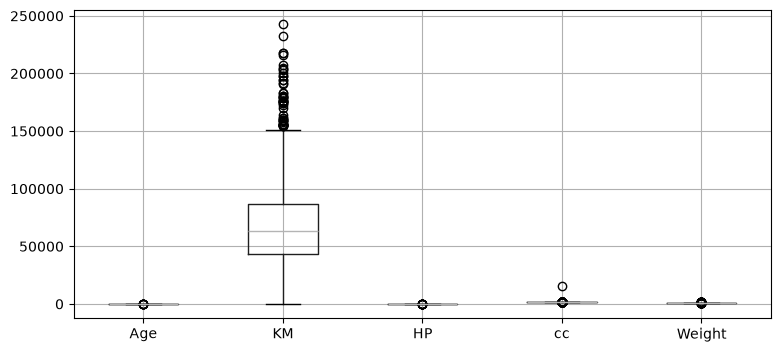

In [63]:
plt.figure(figsize=(9,4))
con_cols.boxplot()
plt.show()

In [64]:
#### outlier capping
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    upper_extreme= Q3+1.5*IQR
    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)
for col in con_cols.select_dtypes(include=['int','float']).columns:
    outlier_capping(features,col)

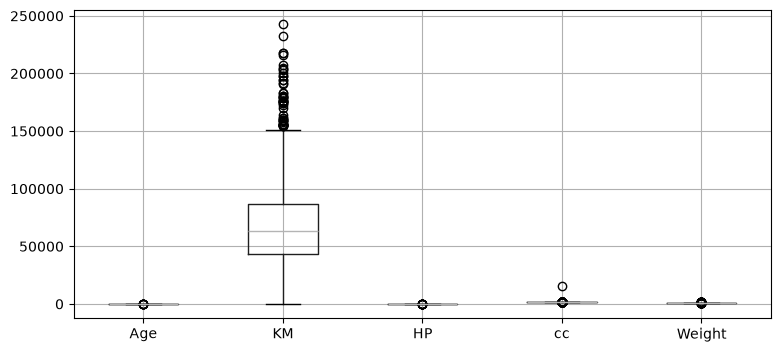

In [65]:
plt.figure(figsize=(9,4))
con_cols.boxplot()
plt.show()

In [66]:
features=pd.get_dummies(features, columns=['Fuel_Type'], drop_first=True, dtype=int)

In [67]:
df1=pd.concat([features,target],axis=1)

In [68]:
df1.columns

Index(['Age', 'KM', 'HP', 'Automatic', 'cc', 'Doors', 'Gears', 'Weight',
       'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Price'],
      dtype='str')

In [69]:
corr=df1.corr()

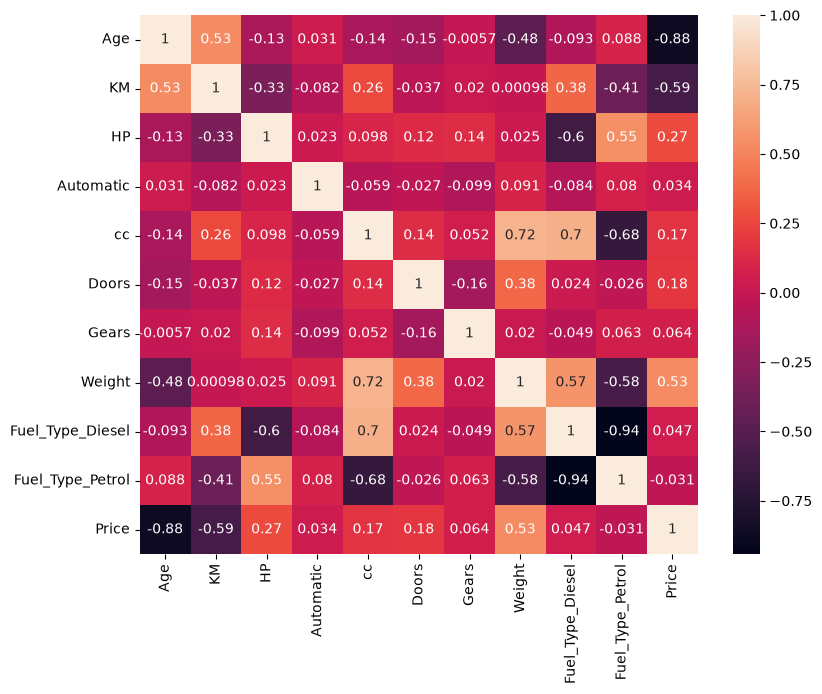

In [70]:
plt.figure(figsize=(9,7))
sns.heatmap(corr,annot=True)
plt.show()

In [71]:
from sklearn.feature_selection import f_regression

In [72]:
f_reg=f_regression(features,target)

In [73]:
pd.Series(f_reg[0])

0    4724.236988
1     752.843420
2     108.895688
3       1.651392
4      41.835924
5      49.992258
6       5.862507
7     574.360800
8       3.120188
9       1.410328
dtype: float64

In [74]:
pd.Series(f_reg[0],index=features.columns)

Age                 4724.236988
KM                   752.843420
HP                   108.895688
Automatic              1.651392
cc                    41.835924
Doors                 49.992258
Gears                  5.862507
Weight               574.360800
Fuel_Type_Diesel       3.120188
Fuel_Type_Petrol       1.410328
dtype: float64

In [75]:
#check multicolinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [76]:
vif=pd.DataFrame()
vif['Features']=features.columns
vif['Scores']=[variance_inflation_factor(features.values,i) for i in range(len(features.columns))]

In [77]:
vif

,Features,Scores
0,Age,18.373317
1,KM,9.820160
2,HP,608.775439
3,Automatic,1.160278
4,cc,1103.424774
5,Doors,24.615412
6,Gears,687.892091
7,Weight,1055.997573
8,Fuel_Type_Diesel,30.350693
9,Fuel_Type_Petrol,75.887243


2.Split the dataset into training and testing sets (e.g., 80% training, 20% testing).

In [78]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [79]:
x_train,x_test,y_train,y_test=train_test_split(features,target,test_size=0.2,random_state=100)

In [80]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((1148, 10), (287, 10), (1148,), (287,))

In [81]:
std_sca=StandardScaler()

In [82]:
x_train[['Age', 'KM', 'HP', 'cc', 'Weight']]=std_sca.fit_transform(x_train[['Age', 'KM', 'HP', 'cc', 'Weight']])
x_test[['Age', 'KM', 'HP', 'cc', 'Weight']]=std_sca.transform(x_test[['Age', 'KM', 'HP', 'cc', 'Weight']])

In [83]:
x_train.head()

,Age,KM,HP,Automatic,cc,Doors,Gears,Weight,Fuel_Type_Diesel,Fuel_Type_Petrol
108,-1.940533,-1.748188,0.689004,0,0.255237,3,5,0.954608,0,1
1280,1.182405,0.176456,-1.123604,1,-1.492799,4,5,-1.387370,0,1
858,0.320905,-0.079609,0.689004,0,0.255237,5,5,0.173948,0,1
903,0.482436,-0.247509,0.689004,0,0.255237,5,5,0.173948,0,1
373,-1.240564,-1.478104,-0.292825,0,-0.910121,5,5,0.434168,0,1


3.Build a multiple linear regression model using the training dataset. Interpret the coefficients of the model. Build a minimum of 3 different models.       4.Evaluate the performance of the model using appropriate evaluation metrics on the testing dataset.

In [84]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,root_mean_squared_error

In [85]:
model1=LinearRegression()
model1.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[-2148.94, -625.04, 1679.9 ,..., 1165.6 , 6888.63, 1201.58]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['Age','KM','HP',...,'Weight','Fuel_Type_Diesel','Fuel_Type_Petrol']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5062
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [86]:
y_pred=model1.predict(x_test)
r1,r2=r2_score(y_test,y_pred),root_mean_squared_error(y_test,y_pred) #model-1 accuracy
print('model 1 accuracy=',r1)
print("root mean squared error=",r2)

model 1 accuracy= 0.8518098959508298
root mean squared error= 1329.8575133402232


In [87]:
#creating model-2 by dropping 'Fuel_type_petrol' because it got low value in f_regression
x_train_reduced=x_train.drop(columns=['Fuel_Type_Petrol'])
x_test_reduced=x_test.drop(columns=['Fuel_Type_Petrol'])

In [88]:
model2=LinearRegression()
model2.fit(x_train_reduced,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[-2147.98, -659.8 , 1670.47,..., 889.75, 1120.44, 5773.28]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['Age','KM','HP',...,'Gears','Weight','Fuel_Type_Diesel']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5824
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


In [89]:
y_pred1=model2.predict(x_test_reduced)
r1,r2=r2_score(y_test,y_pred1),root_mean_squared_error(y_test,y_pred1) #model-2 accuracy
print('model 1 accuracy=',r1)
print("root mean squared error=",r2)

model 1 accuracy= 0.8493010178285468
root mean squared error= 1341.0675974943526


In [90]:
model3=LinearRegression()
#creating model-2 by dropping 'Automatic' and 'Fuel_type_petrol' because it got low value in f_regression
x_train_reduced=x_train.drop(columns=['Automatic','Fuel_Type_Petrol'])
x_test_reduced=x_test.drop(columns=['Automatic','Fuel_Type_Petrol'])
model3.fit(x_train_reduced,y_train)
y_pred=model3.predict(x_test_reduced)
r1,r2=r2_score(y_test,y_pred),root_mean_squared_error(y_test,y_pred) #model-3 accuracy
print('model 1 accuracy=',r1)
print("root mean squared error=",r2)

model 1 accuracy= 0.8487339022464707
root mean squared error= 1343.5886037431019


5.Apply Lasso and Ridge methods on the model.

In [91]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error

In [92]:
#RIDGE REGRESSION
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(x_train, y_train)

# Predict and evaluate
y_pred_ridge = ridge_model.predict(x_test)
r2_ridge = r2_score(y_test, y_pred_ridge)
rmse=root_mean_squared_error(y_test,y_pred_ridge)

print(f"R-squared: {r2_ridge:.4f}")
print(f"Root mean squared error: {rmse:.4f}")

R-squared: 0.8488
Root mean squared error: 1343.4158


In [93]:
#LASSO REGRESSION
lasso_model = Lasso(alpha=1.0)
lasso_model.fit(x_train, y_train)

# Predict and evaluate
y_pred_lasso = lasso_model.predict(x_test)
r2_lasso = r2_score(y_test, y_pred_lasso)
rmse=root_mean_squared_error(y_test,y_pred_lasso)

print(f"R-squared: {r2_lasso:.4f}")
print(f"Root mean squared error: {rmse:.4f}")

R-squared: 0.8511
Root mean squared error: 1332.9317


Interview Questions:        
1.What is Normalization & Standardization and how is it helpful?


In [94]:
print("Normalization rescales the data so that all values fall within a range of 0 and 1.\nStandardization centers the data around the mean with a unit standard deviation. This means the rescaled \nfeature will have a mean of 0 and a standard deviation of 1.")

Normalization rescales the data so that all values fall within a range of 0 and 1.
Standardization centers the data around the mean with a unit standard deviation. This means the rescaled 
feature will have a mean of 0 and a standard deviation of 1.


2.What techniques can be used to address multicollinearity in multiple linear regression?

In [95]:
print("combaining features, applying PCA,using reguralization techniques can be used when multicollinearity occured.")

combaining features, applying PCA,using reguralization techniques can be used when multicollinearity occured.
